This notebook creates a CMD in both apparent and absolute magnitude to compare candidate sources with models, JADES galaxies, and TRILEGAL simulated star populations. It is accompanied by a second notebook (photometry_compiler.ipynb) which reformats JADES fits files and creates a photometry table of all the candidate sources in each observed filter.

Dependencies:
* matplotlib
* numpy
* astropy
* astroquery
* pandas
* glob
* cmcrameri

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import glob

from astropy.table import Table
from astropy.io import fits
from astroquery.simbad import Simbad

%matplotlib inline


## Open photometry data file for your targets

In [2]:
tab = Table.read('photometry.csv')

## Open and read Sonora-Bobcat models

In [3]:
# Read the model file, skipping the first 11 rows
headers = ['Teff', 'log g', 'mass', 'R/Rsun', 'Y', 'log Kzz', 'F070W', 'F090W', 'F115W', 'F140M', 'F150W', 'F150W2', 'F162M', 'F164N', 'F182M', 'F187N', 'F200W', 'F210M', 'F212N', 'F250M', 'F277W', 'F300M', 'F322W2', 'F323N', 'F335M', 'F356W', 'F360M', 'F405N', 'F410M', 'F430M', 'F444W', 'F460M', 'F466N', 'F470N', 'F480M', 'F560W', 'F770W', 'F1000W', 'F1065C', 'F1130W', 'F1140C', 'F1280W', 'F1500W', 'F1550C', 'F1800W', 'F2100W', 'F2300C', 'F2550W', 'FND']

file_path = 'models/bobcat_evolution_and_photometery/photometry_tables/mag_table_JWST+0.5'
df = pd.read_csv(file_path, skiprows=11, header=None, sep='\s+', names = headers)

# Filter rows where logg = 4.0
filtered_df = df[df['log g'] == 4.0]

# Extract the desired filter columns
extracted_df = filtered_df[['F250M', 'F444W']]

# Convert to NumPy arrays
F250Mlogg4 = extracted_df['F250M'].to_numpy()
F444Wlogg4 = extracted_df['F444W'].to_numpy()

In [4]:
# Filter rows where logg = 3.0
filtered_df = df[df['log g'] == 3.0]

# Extract the desired filter columns
extracted_df = filtered_df[['F250M', 'F444W']]

# Convert to NumPy arrays
F250Mlogg3 = extracted_df['F250M'].to_numpy()
F444Wlogg3 = extracted_df['F444W'].to_numpy()

## Set target and parallax of the target

In [5]:
target = 'HIP-65426'
source  = 'b'
plval = 9.3031

## load JADES galaxy photometry

In [6]:
# Load the prepared JADES photometry
jades_color250, jades_mag_f444w_250, jades_cmd_density_250 = np.loadtxt('jades_cmd_f250m_f444w_kron.dat', unpack = True)
print(len(jades_color250))

45405


## TRILEGAL synthetic star population
A synthetic TRILEGAL population for the line of sight of your given target can be obtained here: https://stev.oapd.inaf.it/cgi-bin/trilegal

## Maximal version of the CMD

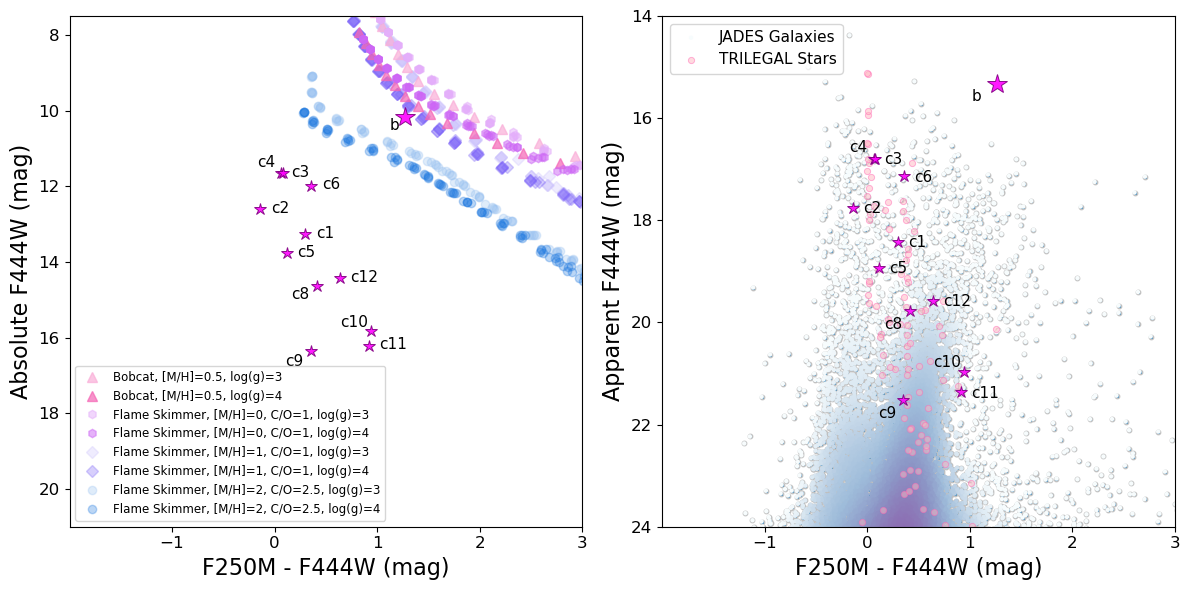

In [7]:
jades_clim=[0.005, 1]
jcmap='bone_r'
jcmap = 'BuPu'

logage = np.log10(14.e6) # appropriate age for HIP 65426


fig = plt.figure(figsize=(12, 6))
        
        
ax = fig.add_subplot(121)
ax2 = fig.add_subplot(122)

dmod = 5.*np.log10((1000. / plval) / 10.)

########### PLOT MODELS #####################

# Sonora-Bobcat
ax.plot(F250Mlogg3 - F444Wlogg3, F444Wlogg3, linestyle='None', marker='^', color='#FAAED8', alpha=0.7, label='Bobcat, [M/H]=0.5, log(g)=3', markersize = 7)
ax.plot(F250Mlogg4 - F444Wlogg4, F444Wlogg4, linestyle='None', marker='^', color='#F566B5', alpha=0.7, label='Bobcat, [M/H]=0.5, log(g)=4', markersize = 7)


# Flame Skimmer models
for fsfile in glob.glob('models/flame_skimmer_publication/deq/JWST/mh+0.0_co1.0_mag.txt'):
    #print(fsfile)
    fstab = Table.read(fsfile, format='ascii')
    ind = np.where((fstab['Teff'] > 100.0) & (fstab['log(g)'] == 3))
    ax.plot(fstab['F250M'][ind] - fstab['F444W'][ind], fstab['F444W'][ind], linestyle='None', marker='h', alpha=0.5, label='Flame Skimmer, [M/H]=0, C/O=1, log(g)=3', color='#E4AEFA', zorder = 2)#, mec='#CD66F5') # pale violet

    ind = np.where((fstab['Teff'] > 100.0) & (fstab['log(g)'] == 4))
    ax.plot(fstab['F250M'][ind] - fstab['F444W'][ind], fstab['F444W'][ind], linestyle='None', marker='h', alpha=0.5, label='Flame Skimmer, [M/H]=0, C/O=1, log(g)=4', color='#CD66F5', zorder = 2) # deep lavender
    
for fsfile in glob.glob('models/flame_skimmer_publication/deq/JWST/mh+1.0_co1.0_mag.txt'):
    #print(fsfile)
    fstab = Table.read(fsfile, format='ascii')
    ind = np.where((fstab['Teff'] > 100.0) & (fstab['log(g)'] == 3.))
    ax.plot(fstab['F250M'][ind] - fstab['F444W'][ind], fstab['F444W'][ind], linestyle='None', marker='D', alpha=0.3, label='Flame Skimmer, [M/H]=1, C/O=1, log(g)=3', color='#CBC1FC', zorder = 1)#, mec='#7C63F8')  # pink
    
    ind = np.where((fstab['Teff'] > 100.0) & (fstab['log(g)'] == 4.))
    ax.plot(fstab['F250M'][ind] - fstab['F444W'][ind], fstab['F444W'][ind], linestyle='None', marker='D', alpha=0.3, label='Flame Skimmer, [M/H]=1, C/O=1, log(g)=4', color='#7C63F8', zorder = 1)  # warm pink
    
for fsfile in glob.glob('models/flame_skimmer_publication/deq/JWST/mh+2.0_co2.5_mag.txt'):
    #print(fsfile)
    fstab = Table.read(fsfile, format='ascii')
    ind = np.where((fstab['Teff'] > 100.0) & (fstab['log(g)'] == 3.))
    ax.plot(fstab['F250M'][ind] - fstab['F444W'][ind], fstab['F444W'][ind], linestyle='None', marker='o', alpha=0.3, label='Flame Skimmer, [M/H]=2, C/O=2.5, log(g)=3', color='#98C1F1', zorder = 0)#, mec='#1F79E0')
    
    ind = np.where((fstab['Teff'] > 100.0) & (fstab['log(g)'] == 4.))
    ax.plot(fstab['F250M'][ind] - fstab['F444W'][ind], fstab['F444W'][ind], linestyle='None', marker='o', alpha=0.3, label='Flame Skimmer, [M/H]=2, C/O=2.5, log(g)=4', color='#1F79E0', zorder = 0)  # dark sky blue

    
  
########### PLOT JADES GALAXIES #####################
jades_mags = (30,10)
inBounds = (jades_color250 >= ax.get_xlim()[0])&(jades_color250 <= ax.get_xlim()[1])&(jades_mag_f444w_250 >= jades_mags[1])&(jades_mag_f444w_250 <= jades_mags[0])
ax2.scatter(jades_color250[inBounds], jades_mag_f444w_250[inBounds], zorder=0.1, rasterized=True, s=10, edgecolor='silver', lw=1)
ax2.scatter(jades_color250[inBounds], jades_mag_f444w_250[inBounds], c=jades_cmd_density_250[inBounds], zorder=0.2, rasterized=True, s=10, norm=mpl.colors.LogNorm(*jades_clim, clip=True), cmap=jcmap, edgecolor='None', label = 'JADES Galaxies')


########### PLOT TRILEGAL STARS #####################

trilegal = Table.read('trilegal_hip65426.dat', format='ascii')

# scale area (trilegal model is for 0.2 degrees^2, assume actual FoV is 5"x5" 
areascale = ((5. / 3600.)**2) #/ (0.2)
ntrilegalobj = (areascale*len(trilegal))
#print(areascale, ntrilegalobj, len(trilegal))

trilegal_color = trilegal['F250M'] - trilegal['F444W']
trilegal_mag_f444w = trilegal['F444W']

inBounds = (trilegal_color >= ax.get_xlim()[0])&(trilegal_color <= ax.get_xlim()[1])&(trilegal_mag_f444w >= jades_mags[1])&(trilegal_mag_f444w <= jades_mags[0])

trilegal_samples = trilegal[np.random.randint(len(trilegal), size=100)]
    
trilegal_color = trilegal_samples['F250M'] - trilegal_samples['F444W']
trilegal_mag_f444w = trilegal_samples['F444W']
    
inBounds = (trilegal_color >= ax.get_xlim()[0])&(trilegal_color <= ax.get_xlim()[1])&(trilegal_mag_f444w >= jades_mags[1])&(trilegal_mag_f444w <= jades_mags[0])
ax2.scatter(trilegal_color[inBounds], trilegal_mag_f444w[inBounds], zorder=0.5, rasterized=True, s=20, fc = 'lightpink', ec='hotpink', lw=0.7, label = 'TRILEGAL Stars', alpha = 0.5)


########### Absolute CMD #############
ind = np.where((tab['Source'] == source)) 

mag444 = tab['APPMAG_F444W']
mag250 = tab['APPMAG_F250M']
sourcenum = tab['Source']

fontsize = 11
for i in range(len(mag444)-1):
    ms = 9
    if sourcenum[i] == 'b':
        ms = 15
        color = 'Fuchsia'
        mec = 'purple'
    else:
        color = 'Fuchsia'
        mec = 'purple'
    ax.plot(mag250[i] - mag444[i], mag444[i] - dmod, mec=mec, mew = 0.7, mfc=color, marker='*', alpha=0.9, linestyle='None', markersize = ms)
    if sourcenum[i] == 'c10':
        ax.text(mag250[i] - mag444[i] - 0.3, mag444[i] - dmod - 0.1, sourcenum[i], fontsize=fontsize)
    elif sourcenum[i] == 'b':
        ax.text(mag250[i] - mag444[i] - 0.15, mag444[i] - dmod + 0.35, sourcenum[i], fontsize=fontsize)
    elif sourcenum[i] == 'c9' :
        ax.text(mag250[i] - mag444[i] - 0.25, mag444[i] - dmod + 0.40, sourcenum[i], fontsize=fontsize)
    elif sourcenum[i] == 'c8':
        ax.text(mag250[i] - mag444[i] - 0.25, mag444[i] - dmod + 0.35, sourcenum[i], fontsize=fontsize)
    elif sourcenum[i] == 'c4':
        ax.text(mag250[i] - mag444[i] - 0.25, mag444[i] - dmod - 0.15, sourcenum[i], fontsize=fontsize)
    else:
        ax.text(mag250[i] - mag444[i] + 0.1, mag444[i] - dmod + 0.1, sourcenum[i], fontsize=fontsize)


########### Apparent CMD #####################

for i in range(len(mag444)-1):
    ms = 9
    if sourcenum[i] == 'b':
        ms = 15
    ax2.plot(mag250[i] - mag444[i], mag444[i], mec='purple', mew = 0.7, mfc='Fuchsia', marker='*', alpha=0.9, linestyle='None', markersize = ms)
    if sourcenum[i] == 'c10':
        ax2.text(mag250[i] - mag444[i] - 0.3, mag444[i] - 0.1, sourcenum[i], fontsize=fontsize)
    elif sourcenum[i] == 'c9' or sourcenum[i] == 'b':
        ax2.text(mag250[i] - mag444[i] - 0.25, mag444[i] + 0.35, sourcenum[i], fontsize=fontsize)
    elif sourcenum[i] == 'c8':
        ax2.text(mag250[i] - mag444[i] - 0.25, mag444[i] + 0.35, sourcenum[i], fontsize=fontsize)
    elif sourcenum[i] == 'c4':
        ax2.text(mag250[i] - mag444[i] - 0.25, mag444[i] - 0.15, sourcenum[i], fontsize=fontsize)
    else:
        ax2.text(mag250[i] - mag444[i] + 0.1, mag444[i] + 0.1, sourcenum[i], fontsize=fontsize)


xticks = [-1,0,1,2,3]
ax.set_xlabel('F250M - F444W (mag)', fontsize=16)
ax.set_ylabel('Absolute F444W (mag)', fontsize=16)
ax.set_xlim((-2, 3))
ax.set_ylim((21, 7.5))
ax.legend(loc='lower left', fontsize=fontsize-2.5)
ax2.legend(loc='upper left', fontsize=fontsize)
ax2.set_xlabel('F250M - F444W (mag)', fontsize=16)
ax2.set_ylabel('Apparent F444W (mag)', fontsize=16)
ax2.set_xlim(ax.get_xlim())
ax2.set_ylim((24,14))
ax2.set_xticks(xticks)
ax2.tick_params(labelsize = 12)
ax.set_xticks(xticks)
ax.tick_params(labelsize = 12)


save_path = 'cmd_mega'
plt.tight_layout()
plt.savefig(save_path, dpi = 350)
